# Fase 3 por dentro: la arquitectura moderna paso a paso

Cada pieza nueva de `leon/model.py`, aislada y con números pequeños:

1. RMSNorm frente a LayerNorm.
2. RoPE: posición como rotación.
3. SwiGLU: un MLP con compuerta.
4. GQA y el tamaño del KV cache.
5. El KV cache en acción: misma salida, mucho menos trabajo.
6. El coste oculto del vocabulario: la memoria de los logits.
7. Batches desde disco con `np.memmap` y bits por byte.

Todo corre en CPU en menos de un minuto. La sección 7 necesita los `.bin` de `phases/2_tokenizer/encode.py`.

In [1]:
import math
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
from leon.model import KVCache, Leon, LeonConfig, RMSNorm, apply_rope, precompute_rope

## 1. RMSNorm frente a LayerNorm

- LayerNorm: `(x - media) / desviación · g + b`.
- RMSNorm: `x / rms(x) · g`, donde `rms(x) = sqrt(media(x²))`.

RMSNorm no centra el vector ni tiene bias. Sale más barato y, en la práctica, entrena igual de bien. Ambas dejan el vector con una escala fija, que es lo que necesitan las capas siguientes.

In [2]:
torch.manual_seed(0)
x = torch.randn(1, 8) * 5 + 2  # large scale, nonzero mean
ln = nn.LayerNorm(8, elementwise_affine=False)(x)
rms = RMSNorm(8, 1e-5)(x)
for name, v in [("x", x), ("LayerNorm", ln), ("RMSNorm", rms.detach())]:
    print(f"{name:9s}: {v.numpy().round(2)} | media {v.mean():+.3f} | rms {v.pow(2).mean().sqrt():.3f}")

x        : [[ 9.7   0.53 -8.89  4.84 -3.42 -4.99  4.02  6.19]] | media +0.997 | rms 6.001
LayerNorm: [[ 1.47 -0.08 -1.67  0.65 -0.75 -1.01  0.51  0.88]] | media -0.000 | rms 1.000
RMSNorm  : [[ 1.62  0.09 -1.48  0.81 -0.57 -0.83  0.67  1.03]] | media +0.166 | rms 1.000


## 2. RoPE: la posición como una rotación

En la fase 1 se **sumaba** a cada token un vector de posición aprendido. RoPE, en cambio, **rota** los vectores `q` y `k`: cada par de canales `(x₀, x₁)` gira un ángulo `posición · θᵢ`.

En 2D se ve directamente. El mismo vector en las posiciones 0 a 5:

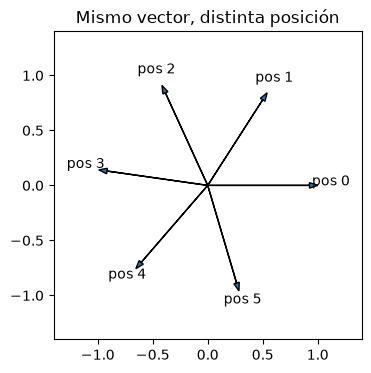

In [3]:
cos, sin = precompute_rope(head_dim=2, max_len=6, theta=10000.0)  # one pair -> one frequency (theta_0 = 1 rad/pos)
v = torch.tensor([[[[1.0, 0.0]]]])
plt.figure(figsize=(4, 4))
for pos in range(6):
    r = apply_rope(v, cos[pos : pos + 1], sin[pos : pos + 1])[0, 0, 0]
    plt.arrow(0, 0, r[0].item(), r[1].item(), head_width=0.05, length_includes_head=True)
    plt.annotate(f"pos {pos}", (r[0].item() * 1.12, r[1].item() * 1.12), ha="center")
plt.xlim(-1.4, 1.4)
plt.ylim(-1.4, 1.4)
plt.gca().set_aspect("equal")
plt.title("Mismo vector, distinta posición")
plt.show()

**La propiedad clave**: si `q` está en la posición `m` y `k` en la `n`, el producto `q·k` depende solo de `m - n`, porque rotar ambos el mismo ángulo extra no cambia el ángulo entre ellos. El modelo ve **distancias**, no posiciones absolutas.

In [4]:
torch.manual_seed(0)
head_dim = 64
cos, sin = precompute_rope(head_dim, 512, 10000.0)
q, k = torch.randn(1, 1, 1, head_dim), torch.randn(1, 1, 1, head_dim)


def score(m, n):
    qm = apply_rope(q, cos[m : m + 1], sin[m : m + 1])
    kn = apply_rope(k, cos[n : n + 1], sin[n : n + 1])
    return (qm * kn).sum().item()


for m, n in [(5, 2), (105, 102), (400, 397), (5, 0), (105, 100)]:
    print(f"q en {m:3d}, k en {n:3d} (distancia {m - n}): q·k = {score(m, n):+.4f}")

q en   5, k en   2 (distancia 3): q·k = -8.2811
q en 105, k en 102 (distancia 3): q·k = -8.2811
q en 400, k en 397 (distancia 3): q·k = -8.2811
q en   5, k en   0 (distancia 5): q·k = -8.9931
q en 105, k en 100 (distancia 5): q·k = -8.9931


Cada par de canales gira a una velocidad distinta: `θᵢ = 10000^(-2i/d)`. Los primeros pares giran rápido y distinguen distancias cortas; los últimos giran muy despacio y distinguen distancias largas. Es como las agujas de un reloj: segundero, minutero y horario.

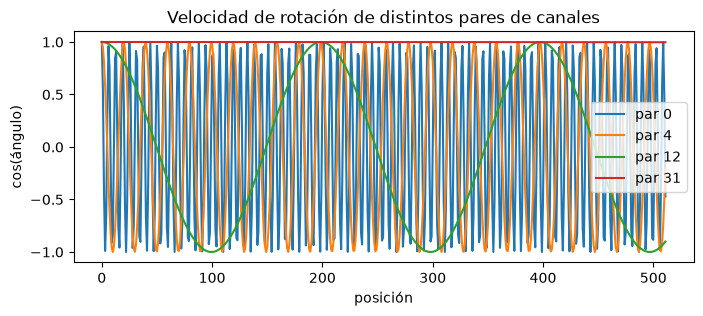

In [5]:
cos, sin = precompute_rope(64, 512, 10000.0)
plt.figure(figsize=(8, 3))
for i in [0, 4, 12, 31]:
    plt.plot(cos[:, i], label=f"par {i}")
plt.xlabel("posición")
plt.ylabel("cos(ángulo)")
plt.title("Velocidad de rotación de distintos pares de canales")
plt.legend()
plt.show()

## 3. SwiGLU: un MLP con compuerta

- MLP de la fase 1: `down(gelu(up(x)))`.
- SwiGLU: `down(silu(gate(x)) · up(x))`. La rama `gate` decide, para cada unidad oculta y cada token, cuánto deja pasar de la rama `up`.

Tiene tres matrices en vez de dos, así que la capa oculta se reduce de `4d` a `~8/3·d` para que el número de parámetros sea el mismo.

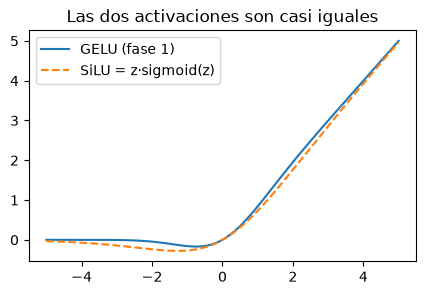

MLP GELU 4d   : 2 · d · 4d     = 2,097,152 parámetros
SwiGLU 1408: 3 · d · hidden = 2,162,688 parámetros


In [6]:
z = torch.linspace(-5, 5, 200)
plt.figure(figsize=(5, 3))
plt.plot(z, F.gelu(z), label="GELU (fase 1)")
plt.plot(z, F.silu(z), label="SiLU = z·sigmoid(z)", linestyle="--")
plt.legend()
plt.title("Las dos activaciones son casi iguales")
plt.show()

d = 512
cfg = LeonConfig(n_embd=d)
print(f"MLP GELU 4d   : 2 · d · 4d     = {2 * d * 4 * d:,} parámetros")
print(f"SwiGLU {cfg.ffn_hidden}: 3 · d · hidden = {3 * d * cfg.ffn_hidden:,} parámetros")

La diferencia no está en la activación, sino en la **multiplicación por la compuerta**. Le da al MLP una forma de "if" suave: la misma unidad puede activarse o apagarse según el contexto del token.

## 4. GQA: compartir keys y values

En la atención multi-head clásica cada cabeza de query tiene su propia key y su propio value. En GQA, grupos de cabezas de query comparten la misma key/value:

- MHA: 8 query, 8 kv.
- GQA: 8 query, 4 kv (cada kv atiende a 2 queries).
- MQA: 8 query, 1 kv.

En el código basta un `repeat_interleave`:

In [7]:
k = torch.arange(4).float().view(1, 4, 1, 1).expand(1, 4, 3, 2)  # 4 kv heads, labelled 0..3
k_rep = k.repeat_interleave(2, dim=1)  # 8 query heads
print("cabeza kv que ve cada una de las 8 cabezas de query:", k_rep[0, :, 0, 0].long().tolist())

cabeza kv que ve cada una de las 8 cabezas de query: [0, 0, 1, 1, 2, 2, 3, 3]


La calidad apenas cambia, pero el **KV cache** (lo que hay que guardar por token al generar) se reduce en proporción. Para un modelo del tamaño de Leon 0.1, en bf16:

In [8]:
n_layer, head_dim, ctx = 10, 64, 1024
for name, n_kv in [("MHA (10 kv)", 10), ("GQA (5 kv)", 5), ("MQA (1 kv)", 1)]:
    per_token = 2 * n_layer * n_kv * head_dim * 2  # k and v, bf16 = 2 bytes
    print(f"{name:12s}: {per_token / 1024:5.1f} KiB por token | {per_token * ctx / 2**20:5.1f} MiB para {ctx} tokens")

MHA (10 kv) :  25.0 KiB por token |  25.0 MiB para 1024 tokens
GQA (5 kv)  :  12.5 KiB por token |  12.5 MiB para 1024 tokens
MQA (1 kv)  :   2.5 KiB por token |   2.5 MiB para 1024 tokens


Con un modelo tan pequeño son pocos MiB. En modelos de 70B con contextos de 100k tokens, el KV cache ocupa decenas de GB y GQA marca la diferencia.

## 5. El KV cache en acción

Sin cache, para generar el token `t` el modelo vuelve a procesar los `t` anteriores, así que generar `n` tokens cuesta del orden de `n²`. Con cache, las keys y values pasadas se guardan y cada paso procesa un solo token.

Mismo modelo y misma salida (greedy), con y sin cache:

In [9]:
torch.manual_seed(0)
cfg = LeonConfig(vocab_size=1000, block_size=512, n_layer=4, n_head=4, n_kv_head=2, n_embd=128)
model = Leon(cfg).eval()
prompt = torch.randint(cfg.vocab_size, (1, 8))

for use_cache in [False, True]:
    start = time.perf_counter()
    out = model.generate(prompt, max_new_tokens=300, temperature=0, use_cache=use_cache)
    print(f"cache={use_cache!s:5}: {time.perf_counter() - start:.2f}s")
    if not use_cache:
        reference = out
print("¿misma salida?", torch.equal(out, reference))

cache = KVCache(cfg, batch_size=1)
model(prompt, cache=cache)  # prefill: the whole prompt in one forward pass
print(f"\ntras el prefill: cache.pos = {cache.pos}, k de la capa 0 = {tuple(cache.k[0, :, :, :cache.pos].shape)} (batch, kv_heads, pos, head_dim)")
model(torch.tensor([[5]]), cache=cache)  # one decoding step
print(f"tras 1 token:    cache.pos = {cache.pos}")

cache=False: 1.09s


cache=True : 0.47s
¿misma salida? True

tras el prefill: cache.pos = 8, k de la capa 0 = (1, 2, 8, 32) (batch, kv_heads, pos, head_dim)
tras 1 token:    cache.pos = 9


## 6. El coste oculto del vocabulario

La última capa produce un logit por token del vocabulario **en cada posición**. Con 92 caracteres (fase 1) es nada. Con 16.384 tokens BPE es lo que más memoria ocupa durante el entrenamiento: por eso `train.py` usa micro-batches de 4.096 tokens y gradient accumulation.

In [10]:
for vocab in [92, 16384]:
    for tokens in [4096, 16384]:
        n = tokens * vocab
        # fp32 logits + log-softmax + their gradient = ~3 copies of 4 bytes, plus the bf16 logits
        approx_gib = n * (3 * 4 + 2) / 2**30
        print(f"vocab {vocab:6,} · {tokens:6,} tokens = {n / 1e6:7.1f}M logits ≈ {approx_gib:5.2f} GiB")

vocab     92 ·  4,096 tokens =     0.4M logits ≈  0.00 GiB
vocab     92 · 16,384 tokens =     1.5M logits ≈  0.02 GiB
vocab 16,384 ·  4,096 tokens =    67.1M logits ≈  0.88 GiB
vocab 16,384 · 16,384 tokens =   268.4M logits ≈  3.50 GiB


`benchmark.py` lo confirmó: con 16.384 tokens por micro-batch la VRAM superaba los 8 GiB, Windows desbordaba a la RAM compartida y la velocidad caía de 10 a 30 veces **sin dar ningún error**.

## 7. Batches desde disco y bits por byte

`TokenFile` abre el `.bin` con `np.memmap` y lee solo las ventanas que pide cada batch.

In [11]:
from leon.data import TokenFile, load_tokenizer

val_path = ROOT / "data" / "wiki_es" / "val.bin"
if val_path.exists():
    tokenizer = load_tokenizer()
    val = TokenFile(val_path)
    print(f"{len(val):,} tokens en disco | {val.bytes_per_token:.3f} bytes/token")
    torch.manual_seed(0)
    x, y = val.get_batch(batch_size=2, block_size=24, device="cpu")
    print("x[0]:", repr(tokenizer.decode(x[0].tolist())))
    print("y[0]:", repr(tokenizer.decode(y[0].tolist())), " <- desplazado un token")

    loss = 3.5  # an example validation loss, in nats per token
    print(f"\nloss {loss} nats/token = {loss / math.log(2):.3f} bits/token = {loss / math.log(2) / val.bytes_per_token:.3f} bits/byte")
else:
    print("Ejecuta: python phases/2_tokenizer/encode.py")

28,435,406 tokens en disco | 4.111 bytes/token
x[0]: ' Kaede y sus amigo pensaban que era igual que Saori , pero más adelante se descubre que Sakura'
y[0]: 'aede y sus amigo pensaban que era igual que Saori , pero más adelante se descubre que Sakura en'  <- desplazado un token

loss 3.5 nats/token = 5.049 bits/token = 1.228 bits/byte


## Conclusión

Ninguna de estas piezas cambia la idea de la fase 1, que sigue siendo atención, MLP y residuales. Cada una mejora un aspecto concreto:

- RMSNorm y SwiGLU: algo de calidad y eficiencia.
- RoPE: posiciones relativas sin parámetros.
- GQA y KV cache: generación barata.

`torch.compile` y el tamaño del micro-batch fijan lo que de verdad cuesta entrenar en esta GPU, y con eso se elige el tamaño de Leon 0.1.